# PRML Lab 5 — QDA, LDA, Gaussian MLE and Naive Bayes for text
**Aryan Tiwari (B20AI056)** · CSL2050 Pattern Recognition & Machine Learning · Winter 2022

In [1]:
import json
import warnings
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Ellipse
from sklearn.model_selection import train_test_split
from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis as QDA, LinearDiscriminantAnalysis as LDA

warnings.filterwarnings('ignore', message='.*encountered in matmul', category=RuntimeWarning)
SEED = 56
sns.set_theme(style='whitegrid')
results = {}
COLORS = ['tab:blue', 'tab:orange', 'tab:green']

def savefig(name):
    plt.savefig(f'figures/{name}.png', dpi=150, bbox_inches='tight')

# Question 1 — QDA and LDA on Iris

### A. Pre-processing, stratified 70:30 split, scatterplots of every feature pair

In [2]:
iris = pd.read_csv('data/iris.csv')
FEATS = ['sepal length', 'sepal width', 'petal length', 'petal width']
iris['class'] = iris['class'].str.replace('Iris-', '')
CLASSES = sorted(iris['class'].unique())
print(iris.shape, '| missing:', iris.isna().sum().sum(), '| duplicates:', iris.duplicated().sum())
print(iris['class'].value_counts().to_dict())
X, y = iris[FEATS].values, iris['class'].map({c: i for i, c in enumerate(CLASSES)}).values
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.3, stratify=y, random_state=SEED)
print('train', X_tr.shape, '| test', X_te.shape, '| test class counts:', np.bincount(y_te))

(150, 5) | missing: 0 | duplicates: 3
{'setosa': 50, 'versicolor': 50, 'virginica': 50}
train (105, 4) | test (45, 4) | test class counts: [15 15 15]


No missing values. The 3 duplicate rows are genuine repeated measurements (iris measurements are rounded to 0.1 cm), so they are kept. All four features are in cm on similar ranges. QDA/LDA are not affected by rescaling, so no normalisation is needed. The split is **stratified**, so the test set has exactly 15 flowers of each species.

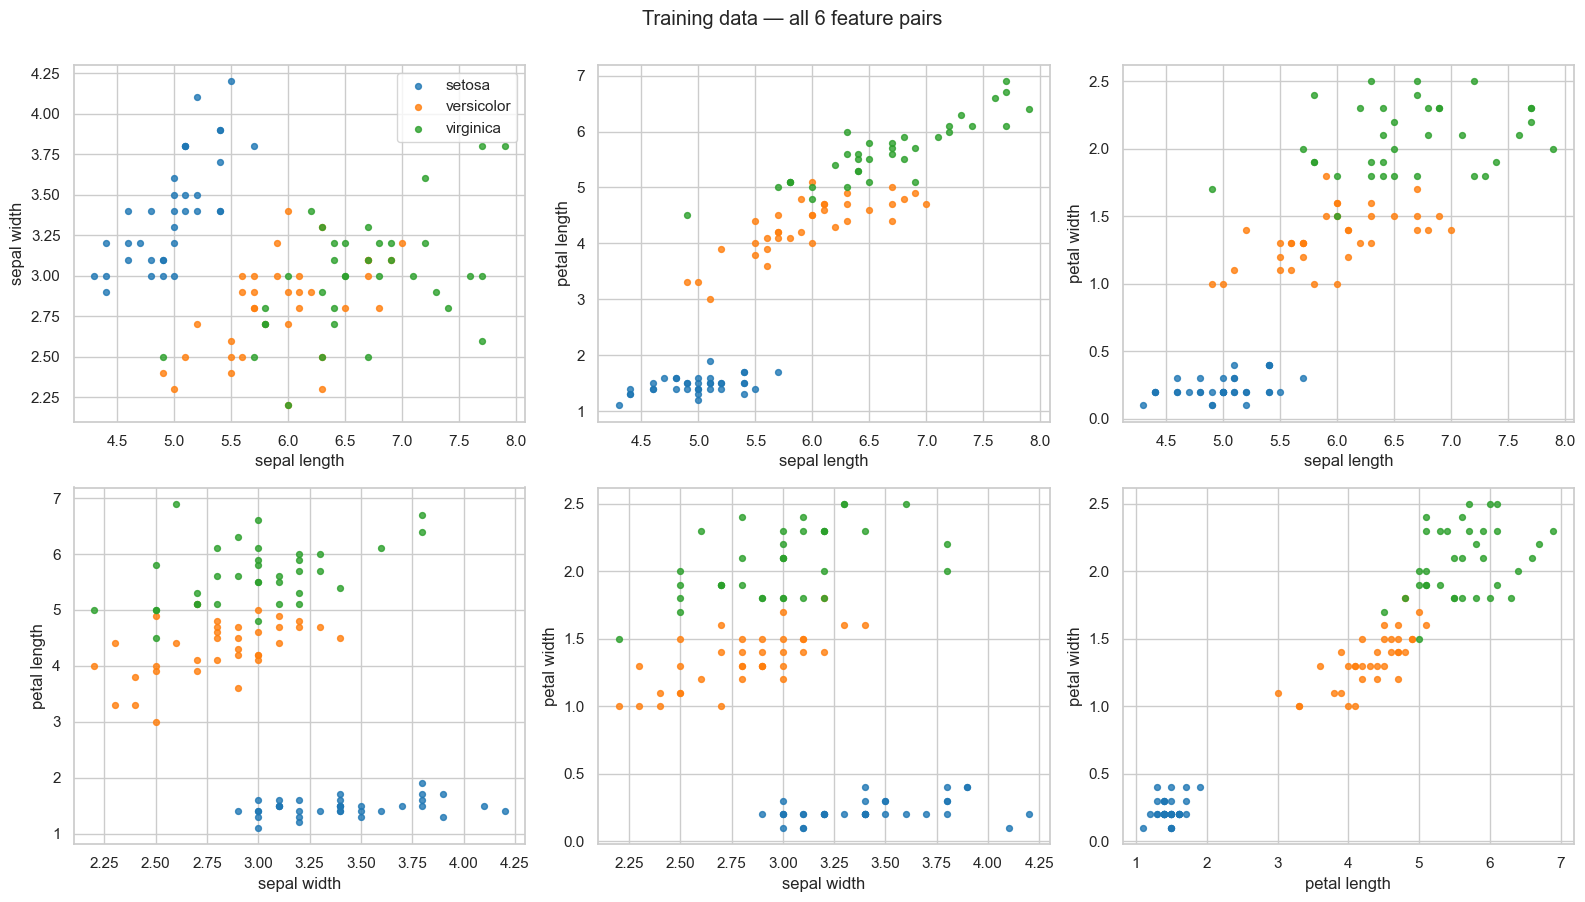

In [3]:
fig, ax = plt.subplots(2, 3, figsize=(16, 9))
for a, (i, j) in zip(ax.flat, combinations(range(4), 2)):
    for k, c in enumerate(CLASSES):
        m = y_tr == k
        a.scatter(X_tr[m, i], X_tr[m, j], s=18, c=COLORS[k], label=c, alpha=0.8)
    a.set_xlabel(FEATS[i]); a.set_ylabel(FEATS[j])
ax[0, 0].legend()
plt.suptitle('Training data — all 6 feature pairs', y=1.0); plt.tight_layout(); savefig('q1_pairs'); plt.show()

### B. Three feature pairs and a QDA model for each
From the scatterplots, the petal features separate the species best. Setosa is always isolated, so the real question for each pair is how much versicolor and virginica overlap. The three pairs chosen:
1. **petal length × petal width** — tight, well-separated clusters;
2. **sepal length × petal length** — petal length does most of the work, and sepal length adds a second direction;
3. **sepal width × petal width** — petal width separates the species, while sepal width gives setosa a different covariance shape (a good test of QDA's per-class covariance).

In [4]:
PAIRS = [(2, 3), (0, 2), (1, 3)]
qda_models = {}
for p in PAIRS:
    qda_models[p] = QDA(store_covariance=True).fit(X_tr[:, p], y_tr)
print('trained', len(qda_models), 'QDA models')

trained 3 QDA models


### C. Mean and covariance of every class Gaussian in each QDA model

In [5]:
param_rows = []
for p, m in qda_models.items():
    print(f'=== {FEATS[p[0]]} × {FEATS[p[1]]}')
    for k, c in enumerate(CLASSES):
        print(f'  {c:11s} mean = {np.round(m.means_[k], 3)}   cov = {np.round(m.covariance_[k], 4).tolist()}')
        param_rows.append({'pair': f'{FEATS[p[0]]} × {FEATS[p[1]]}', 'class': c, 'mean': m.means_[k].round(3).tolist(),
                           'cov': m.covariance_[k].round(4).tolist()})
results['q1_qda_params'] = param_rows

=== petal length × petal width
  setosa      mean = [1.471 0.229]   cov = [[0.0239, 0.0035], [0.0035, 0.0068]]
  versicolor  mean = [4.311 1.343]   cov = [[0.2516, 0.0768], [0.0768, 0.0419]]
  virginica   mean = [5.631 2.071]   cov = [[0.3169, 0.0492], [0.0492, 0.068]]
=== sepal length × petal length
  setosa      mean = [4.983 1.471]   cov = [[0.1173, 0.0233], [0.0233, 0.0239]]
  versicolor  mean = [5.96  4.311]   cov = [[0.2872, 0.2149], [0.2149, 0.2516]]
  virginica   mean = [6.643 5.631]   cov = [[0.459, 0.3377], [0.3377, 0.3169]]
=== sepal width × petal width
  setosa      mean = [3.409 0.229]   cov = [[0.1179, 0.0106], [0.0106, 0.0068]]
  versicolor  mean = [2.806 1.343]   cov = [[0.09, 0.043], [0.043, 0.0419]]
  virginica   mean = [2.989 2.071]   cov = [[0.1299, 0.0508], [0.0508, 0.068]]


### D–E. Decision boundaries and test error

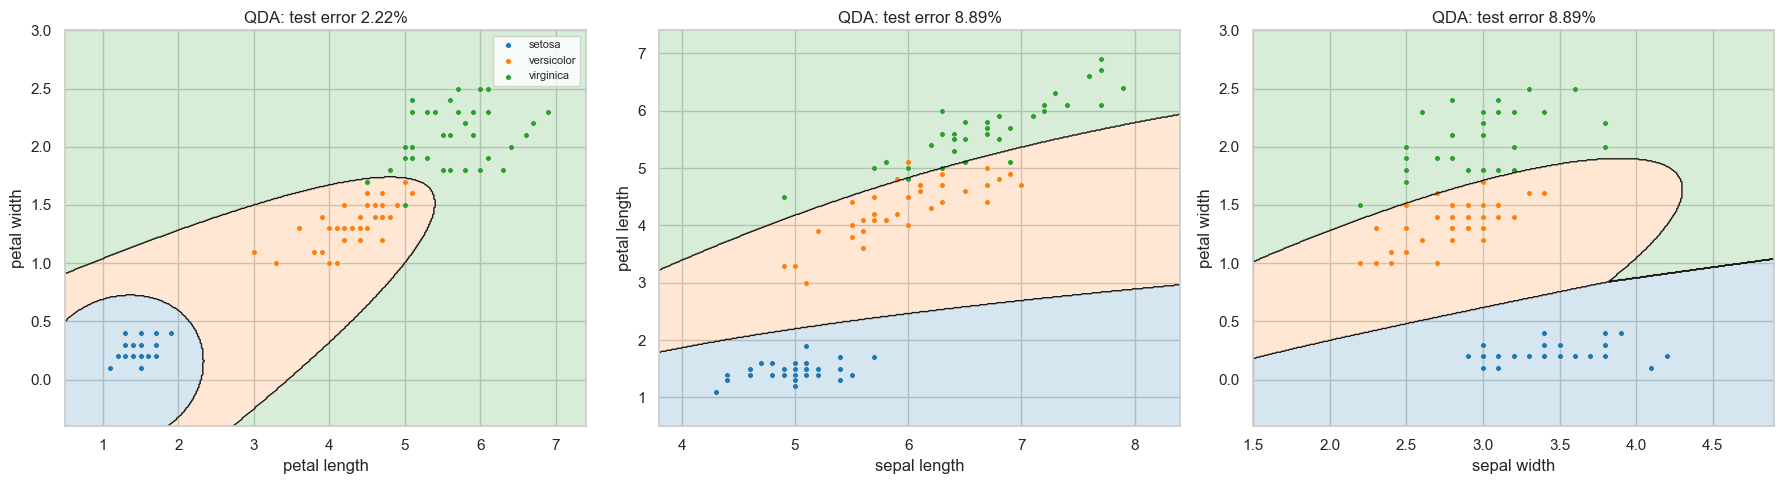

petal length × petal width     0.0222
sepal length × petal length    0.0889
sepal width × petal width      0.0889
Name: QDA test error, dtype: float64

In [6]:
def grid_for(Xp, pad=0.5, n=400):
    x0, x1 = Xp[:, 0].min() - pad, Xp[:, 0].max() + pad
    y0, y1 = Xp[:, 1].min() - pad, Xp[:, 1].max() + pad
    return np.meshgrid(np.linspace(x0, x1, n), np.linspace(y0, y1, n))

def plot_boundary(ax, model, p, title):
    gx, gy = grid_for(X[:, p])
    z = model.predict(np.c_[gx.ravel(), gy.ravel()]).reshape(gx.shape)
    ax.contourf(gx, gy, z, alpha=0.18, levels=[-0.5, 0.5, 1.5, 2.5], colors=COLORS)
    ax.contour(gx, gy, z, levels=[0.5, 1.5], colors='k', linewidths=1)
    for k, c in enumerate(CLASSES):
        m = y_tr == k
        ax.scatter(X_tr[m, p[0]], X_tr[m, p[1]], s=16, c=COLORS[k], label=c, edgecolor='w', linewidth=0.3)
    ax.set_xlabel(FEATS[p[0]]); ax.set_ylabel(FEATS[p[1]]); ax.set_title(title)

errors = {}
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
for a, (p, m) in zip(ax, qda_models.items()):
    err = np.mean(m.predict(X_te[:, p]) != y_te)
    errors[f'{FEATS[p[0]]} × {FEATS[p[1]]}'] = err
    plot_boundary(a, m, p, f'QDA: test error {err:.2%}')
ax[0].legend(fontsize=8)
plt.tight_layout(); savefig('q1_qda_boundaries'); plt.show()
results['q1_qda_test_error'] = errors
pd.Series(errors, name='QDA test error').round(4)

In [7]:
# test errors are tied in steps of 1/45, so also compare log-loss on the test set and the training error
from sklearn.metrics import log_loss
detail = pd.DataFrame({f'{FEATS[p[0]]} × {FEATS[p[1]]}': {
    'test error': np.mean(m.predict(X_te[:, p]) != y_te),
    'train error': np.mean(m.predict(X_tr[:, p]) != y_tr),
    'test log-loss': log_loss(y_te, m.predict_proba(X_te[:, p]))} for p, m in qda_models.items()}).T
best_pair = PAIRS[int(np.argmin(detail['test error'].values + 1e-3 * detail['test log-loss'].values))]
results['q1_qda_detail'] = detail.round(4).to_dict('index')
results['q1_best_pair'] = [FEATS[i] for i in best_pair]
print('best pair:', [FEATS[i] for i in best_pair])
detail.round(4)

best pair: ['petal length', 'petal width']


,test error,train error,test log-loss
petal length × petal width,0.0222,0.0286,0.0761
sepal length × petal length,0.0889,0.0571,0.1557
sepal width × petal width,0.0889,0.0190,0.2601


### F–H. LDA on the best pair: boundary and error, compared with QDA

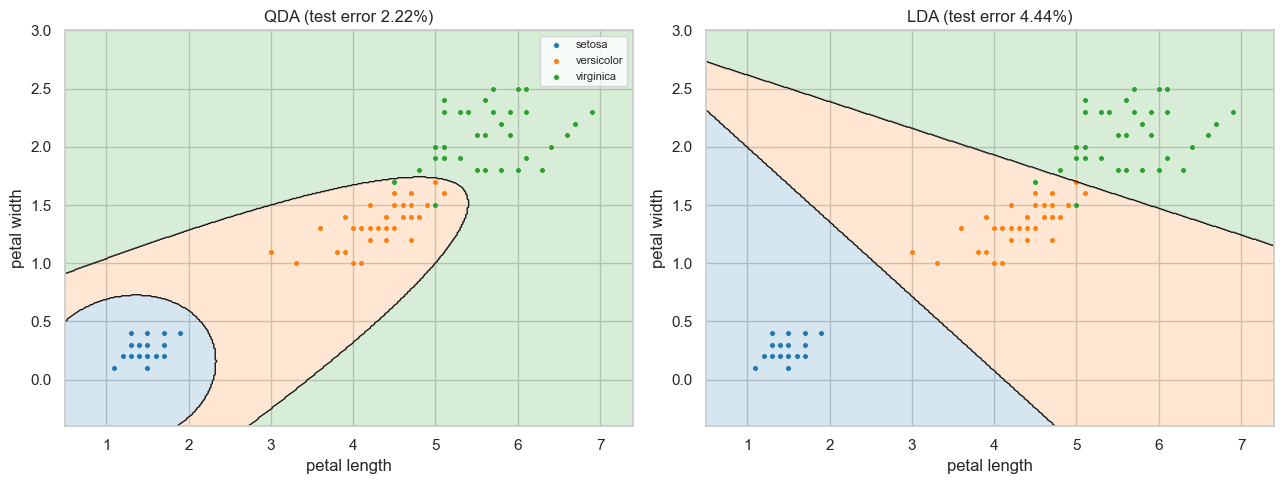

,test error,train error,test log-loss,parameters
QDA,0.0222,0.0286,0.0761,15.0
LDA,0.0444,0.0286,0.1474,9.0


In [8]:
lda = LDA(store_covariance=True).fit(X_tr[:, best_pair], y_tr)
qda_best = qda_models[best_pair]
lda_err = np.mean(lda.predict(X_te[:, best_pair]) != y_te)
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
plot_boundary(ax[0], qda_best, best_pair, f'QDA (test error {detail["test error"].min():.2%})')
plot_boundary(ax[1], lda, best_pair, f'LDA (test error {lda_err:.2%})')
ax[0].legend(fontsize=8)
plt.tight_layout(); savefig('q1_lda_vs_qda'); plt.show()
cmp = pd.DataFrame({
    'QDA': {'test error': np.mean(qda_best.predict(X_te[:, best_pair]) != y_te), 'train error': np.mean(qda_best.predict(X_tr[:, best_pair]) != y_tr),
            'test log-loss': log_loss(y_te, qda_best.predict_proba(X_te[:, best_pair])), 'parameters': 3 * 2 + 3 * 3},
    'LDA': {'test error': lda_err, 'train error': np.mean(lda.predict(X_tr[:, best_pair]) != y_tr),
            'test log-loss': log_loss(y_te, lda.predict_proba(X_te[:, best_pair])), 'parameters': 3 * 2 + 3}}).T
results['q1_lda_vs_qda'] = cmp.round(4).to_dict('index')
results['q1_lda_shared_cov'] = lda.covariance_.round(4).tolist()
cmp.round(4)

### I. The Gaussians learnt by QDA and LDA (1σ and 2σ ellipses)

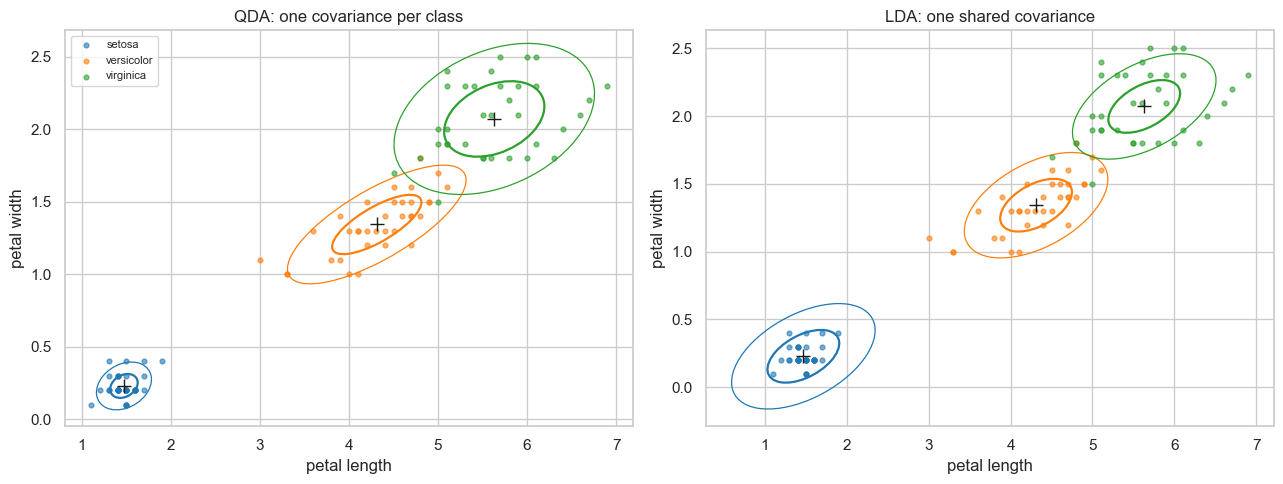

In [9]:
def ellipse(ax, mean, cov, color, ls='-'):
    vals, vecs = np.linalg.eigh(cov)
    angle = np.degrees(np.arctan2(vecs[1, 1], vecs[0, 1]))
    for nsig in (1, 2):
        w, h = 2 * nsig * np.sqrt(vals[1]), 2 * nsig * np.sqrt(vals[0])
        ax.add_patch(Ellipse(mean, w, h, angle=angle, fill=False, color=color, ls=ls, lw=1.6 if nsig == 1 else 0.9))

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for a, (model, covs, title) in zip(ax, [(qda_best, qda_best.covariance_, 'QDA: one covariance per class'),
                                        (lda, [lda.covariance_] * 3, 'LDA: one shared covariance')]):
    for k, c in enumerate(CLASSES):
        m = y_tr == k
        a.scatter(X_tr[m, best_pair[0]], X_tr[m, best_pair[1]], s=12, c=COLORS[k], alpha=0.6, label=c)
        ellipse(a, model.means_[k], covs[k], COLORS[k])
        a.plot(*model.means_[k], 'k+', ms=10)
    a.set_xlabel(FEATS[best_pair[0]]); a.set_ylabel(FEATS[best_pair[1]]); a.set_title(title)
ax[0].legend(fontsize=8)
plt.tight_layout(); savefig('q1_gaussians'); plt.show()

# Question 2 — Gaussian MLE and a Bayes classifier (petal length & width)

In [10]:
P = [2, 3]
Xp_tr, Xp_te = X_tr[:, P], X_te[:, P]

### a. Sample mean and sample covariance (unbiased, divides by n − 1) of each class

In [11]:
def sample_stats(Xc):
    mu = Xc.sum(0) / len(Xc)
    d = Xc - mu
    return mu, d.T @ d / (len(Xc) - 1)

sample_params = {k: sample_stats(Xp_tr[y_tr == k]) for k in range(3)}
for k, c in enumerate(CLASSES):
    mu, S = sample_params[k]
    print(f'{c:11s} mean = {mu.round(3)}  cov = {S.round(4).tolist()}')

def gaussian_contours(ax, params, ls='-', label_prefix=''):
    gx, gy = np.meshgrid(np.linspace(0.5, 7.5, 300), np.linspace(-0.3, 3.0, 300))
    pts = np.c_[gx.ravel(), gy.ravel()]
    for k in range(3):
        mu, S = params[k]
        z = np.exp(compute_log_likelihood(pts, mu, S)).reshape(gx.shape)
        cs = ax.contour(gx, gy, z, levels=4, colors=COLORS[k], linestyles=ls, linewidths=1.1)
    ax.set_xlabel('petal length'); ax.set_ylabel('petal width')

setosa      mean = [1.471 0.229]  cov = [[0.0239, 0.0035], [0.0035, 0.0068]]
versicolor  mean = [4.311 1.343]  cov = [[0.2516, 0.0768], [0.0768, 0.0419]]
virginica   mean = [5.631 2.071]  cov = [[0.3169, 0.0492], [0.0492, 0.068]]


### b. `compute_likelihood` — multivariate Gaussian density from scratch
$$\mathcal N(x;\mu,\Sigma) = \frac{1}{2\pi\,|\Sigma|^{1/2}}\exp\!\Big(-\tfrac12 (x-\mu)^\top\Sigma^{-1}(x-\mu)\Big)$$
The 2×2 determinant and inverse are written out by hand. A log version is also provided, because multiplying many small densities underflows.

max |scratch − scipy| = 3.552713678800501e-15


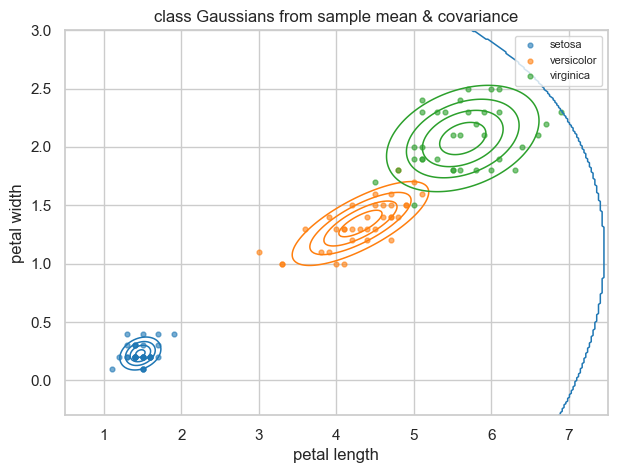

In [12]:
def det2(S):
    return S[0, 0] * S[1, 1] - S[0, 1] * S[1, 0]

def inv2(S):
    return np.array([[S[1, 1], -S[0, 1]], [-S[1, 0], S[0, 0]]]) / det2(S)

def compute_log_likelihood(x, mu, S):
    x = np.atleast_2d(x)
    d = x - mu
    maha = np.einsum('ni,ij,nj->n', d, inv2(S), d)
    return -0.5 * maha - np.log(2 * np.pi) - 0.5 * np.log(det2(S))

def compute_likelihood(x, mu, S):
    return np.exp(compute_log_likelihood(x, mu, S))

# sanity check against scipy (used only for verification)
from scipy.stats import multivariate_normal
mu0, S0 = sample_params[0]
print('max |scratch − scipy| =', np.abs(compute_likelihood(Xp_te, mu0, S0) - multivariate_normal(mu0, S0).pdf(Xp_te)).max())

fig, ax = plt.subplots(figsize=(7, 5))
for k, c in enumerate(CLASSES):
    ax.scatter(*Xp_tr[y_tr == k].T, s=12, c=COLORS[k], alpha=0.6, label=c)
gaussian_contours(ax, sample_params)
ax.set_title('class Gaussians from sample mean & covariance'); ax.legend(fontsize=8)
savefig('q2a_sample_gaussians'); plt.show()

### c. Maximum-likelihood estimation and a Bayes classifier
Maximising $\sum_i \log\mathcal N(x_i;\mu,\Sigma)$ gives $\hat\mu = \frac1n\sum x_i$ and $\hat\Sigma = \frac1n\sum (x_i-\hat\mu)(x_i-\hat\mu)^\top$. This is the *biased* estimator, dividing by n instead of n − 1. Priors are the class frequencies. The Bayes classifier picks $\arg\max_c \; \log P(c) + \log\mathcal N(x;\hat\mu_c,\hat\Sigma_c)$.

In [13]:
def mle(Xc):
    mu = Xc.sum(0) / len(Xc)
    d = Xc - mu
    return mu, d.T @ d / len(Xc)

class GaussianBayes:
    def fit(self, X, y):
        self.classes_ = np.unique(y)
        self.params_ = {k: mle(X[y == k]) for k in self.classes_}
        self.log_prior_ = {k: np.log(np.mean(y == k)) for k in self.classes_}
        return self
    def log_posterior(self, X):
        return np.column_stack([self.log_prior_[k] + compute_log_likelihood(X, *self.params_[k]) for k in self.classes_])
    def predict(self, X):
        return self.classes_[self.log_posterior(X).argmax(1)]

gb = GaussianBayes().fit(Xp_tr, y_tr)
mle_rows = []
for k, c in enumerate(CLASSES):
    mu, S = gb.params_[k]
    print(f'{c:11s} prior = {np.exp(gb.log_prior_[k]):.3f}  mean = {mu.round(3)}  cov = {S.round(4).tolist()}')
    mle_rows.append({'class': c, 'prior': float(np.exp(gb.log_prior_[k])), 'mean': mu.round(3).tolist(), 'cov': S.round(4).tolist()})
results['q2_mle'] = mle_rows
n_per_class = np.bincount(y_tr)[0]
print(f'\nMLE cov = sample cov × (n−1)/n = × {(n_per_class - 1) / n_per_class:.4f} (n = {n_per_class})')

setosa      prior = 0.333  mean = [1.471 0.229]  cov = [[0.0232, 0.0034], [0.0034, 0.0066]]
versicolor  prior = 0.333  mean = [4.311 1.343]  cov = [[0.2444, 0.0747], [0.0747, 0.0407]]
virginica   prior = 0.333  mean = [5.631 2.071]  cov = [[0.3079, 0.0478], [0.0478, 0.066]]

MLE cov = sample cov × (n−1)/n = × 0.9714 (n = 35)


### d. Both sets of Gaussians in one plot

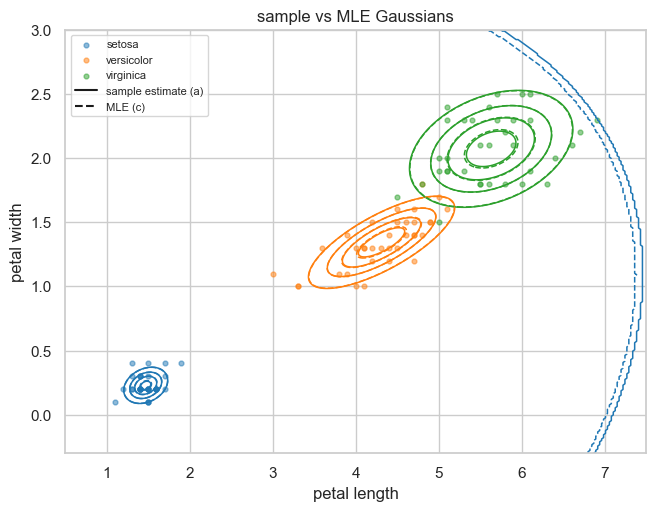

In [14]:
fig, ax = plt.subplots(figsize=(7.5, 5.5))
for k, c in enumerate(CLASSES):
    ax.scatter(*Xp_tr[y_tr == k].T, s=12, c=COLORS[k], alpha=0.5, label=c)
gaussian_contours(ax, sample_params, ls='-')
gaussian_contours(ax, gb.params_, ls='--')
ax.plot([], [], 'k-', label='sample estimate (a)'); ax.plot([], [], 'k--', label='MLE (c)')
ax.set_title('sample vs MLE Gaussians'); ax.legend(fontsize=8)
savefig('q2d_sample_vs_mle'); plt.show()

### e. Test predictions, compared with QDA on the same features

In [15]:
pred_gb = gb.predict(Xp_te)
qda_pl = qda_models[(2, 3)]
q2 = {'scratch Gaussian Bayes (MLE)': np.mean(pred_gb != y_te), 'sklearn QDA (Q1)': np.mean(qda_pl.predict(Xp_te) != y_te)}
agree = np.mean(pred_gb == qda_pl.predict(Xp_te))
results['q2_test_error'] = q2
results['q2_agreement_with_qda'] = float(agree)
print('test error:', {k: round(v, 4) for k, v in q2.items()}, '| prediction agreement:', f'{agree:.2%}')
print(pd.crosstab(pd.Series(np.array(CLASSES)[y_te], name='true'), pd.Series(np.array(CLASSES)[pred_gb], name='predicted')))

test error: {'scratch Gaussian Bayes (MLE)': np.float64(0.0222), 'sklearn QDA (Q1)': np.float64(0.0222)} | prediction agreement: 100.00%
predicted   setosa  versicolor  virginica
true                                     
setosa          15           0          0
versicolor       0          15          0
virginica        0           1         14


# Question 3 — Naive Bayes for 20 Newsgroups
Bag-of-words triples `(docId, termId, count)`. Documents are never expanded into a dense 11k × 61k matrix. Every quantity is accumulated directly from the triples with NumPy indexing (no ML library is used).

In [16]:
def load_triples(path):
    a = np.loadtxt(path, dtype=np.int64)
    return a[:, 0] - 1, a[:, 1] - 1, a[:, 2]        # 0-based doc, term, count

tr_doc, tr_term, tr_cnt = load_triples('data/20news/train.data')
te_doc, te_term, te_cnt = load_triples('data/20news/test.data')
tr_lab = np.loadtxt('data/20news/train.label', dtype=np.int64) - 1
te_lab = np.loadtxt('data/20news/test.label', dtype=np.int64) - 1
groups = [l.split()[0] for l in open('data/20news/train.map')]
V = max(tr_term.max(), te_term.max()) + 1
C = len(groups)
print(f'{len(tr_lab)} train docs, {len(te_lab)} test docs, vocabulary {V}, {C} classes')
unseen = np.setdiff1d(np.unique(te_term), np.unique(tr_term))
print(f'{len(unseen)} distinct test words never appear in training')

11269 train docs, 7505 test docs, vocabulary 61188, 20 classes
7213 distinct test words never appear in training


### 1. Likelihood of the training set (maximum-likelihood, no smoothing)
Multinomial Naive Bayes: $P(c) = N_c/N$ and $P(w\mid c) = \frac{\text{count}(w,c)}{\sum_{w'}\text{count}(w',c)}$. The (log-)likelihood of the training set is
$\sum_d \big[\log P(c_d) + \sum_w n_{dw}\log P(w\mid c_d)\big]$. On the *training* data every word of a class-c document has been seen in class c, so this stays finite.

In [17]:
def word_class_counts(doc, term, cnt, labels):
    counts = np.zeros((C, V))
    np.add.at(counts, (labels[doc], term), cnt)
    return counts

counts = word_class_counts(tr_doc, tr_term, tr_cnt, tr_lab)
class_docs = np.bincount(tr_lab, minlength=C)
log_prior = np.log(class_docs / class_docs.sum())

with np.errstate(divide='ignore'):
    log_lik_mle = np.log(counts / counts.sum(1, keepdims=True))     # -inf where a word never occurs in a class

train_ll = log_prior[tr_lab].sum() + np.sum(tr_cnt * log_lik_mle[tr_lab[tr_doc], tr_term])
zero_frac = np.mean(counts == 0)
results['q3_train_loglik_mle'] = float(train_ll)
results['q3_zero_fraction'] = float(zero_frac)
print(f'training log-likelihood (MLE) = {train_ll:,.0f}  |  {train_ll / tr_cnt.sum():.3f} nats per word token')
print(f'{zero_frac:.1%} of (class, word) pairs have zero count → P(w|c) = 0')

training log-likelihood (MLE) = -19,372,938  |  -7.006 nats per word token


83.6% of (class, word) pairs have zero count → P(w|c) = 0


### 2. Laplace smoothing
$P(w\mid c) = \frac{\text{count}(w,c) + 1}{\sum_{w'}\text{count}(w',c) + |V|}$. Every word gets a small non-zero probability in every class, so one unseen word can no longer zero out a whole document. The cell below shows what goes wrong without it.

In [18]:
def laplace(counts, alpha=1.0):
    return np.log((counts + alpha) / (counts.sum(1, keepdims=True) + alpha * counts.shape[1]))

log_lik = laplace(counts)

def doc_scores(doc, term, cnt, n_docs, log_lik):
    scores = np.zeros((n_docs, C))
    np.add.at(scores, doc, cnt[:, None] * log_lik[:, term].T)
    return scores + log_prior

with np.errstate(invalid='ignore'):
    s_mle = doc_scores(te_doc, te_term, te_cnt, len(te_lab), log_lik_mle)
all_neg_inf = np.mean(np.all(np.isneginf(s_mle), axis=1))
acc_mle = np.mean(np.nan_to_num(s_mle, nan=-np.inf).argmax(1) == te_lab)
train_ll_smooth = log_prior[tr_lab].sum() + np.sum(tr_cnt * log_lik[tr_lab[tr_doc], tr_term])
results['q3_no_smoothing'] = {'test_docs_all_classes_zero': float(all_neg_inf), 'test_acc': float(acc_mle)}
results['q3_train_loglik_laplace'] = float(train_ll_smooth)
print(f'without smoothing: {all_neg_inf:.1%} of test documents get probability 0 under EVERY class; accuracy {acc_mle:.2%}')
print(f'training log-likelihood with Laplace smoothing = {train_ll_smooth:,.0f} (lower than MLE, as expected — smoothing gives up a little fit on the training set)')

without smoothing: 92.7% of test documents get probability 0 under EVERY class; accuracy 9.46%
training log-likelihood with Laplace smoothing = -20,205,369 (lower than MLE, as expected — smoothing gives up a little fit on the training set)


### 3. `naiveBayesClassify(trainData, trainLabels, testData)`

In [19]:
def naiveBayesClassify(trainData, trainLabels, testData, alpha=1.0):
    t_doc, t_term, t_cnt = trainData
    q_doc, q_term, q_cnt = testData
    cnts = np.zeros((C, V))
    np.add.at(cnts, (trainLabels[t_doc], t_term), t_cnt)
    prior = np.log(np.bincount(trainLabels, minlength=C) / len(trainLabels))
    ll = np.log((cnts + alpha) / (cnts.sum(1, keepdims=True) + alpha * V))
    scores = np.zeros((q_doc.max() + 1, C))
    np.add.at(scores, q_doc, q_cnt[:, None] * ll[:, q_term].T)
    return (scores + prior).argmax(1)

pred = naiveBayesClassify((tr_doc, tr_term, tr_cnt), tr_lab, (te_doc, te_term, te_cnt))
acc = np.mean(pred == te_lab)
per_class = pd.Series({g: np.mean(pred[te_lab == k] == k) for k, g in enumerate(groups)}).sort_values()
results['q3_test_acc'] = float(acc)
results['q3_per_class'] = per_class.round(4).to_dict()
print(f'test accuracy = {acc:.4f}')
per_class.round(3)

test accuracy = 0.7811


talk.religion.misc          0.355
comp.os.ms-windows.misc     0.529
misc.forsale                0.592
talk.politics.misc          0.594
sci.electronics             0.659
comp.sys.mac.hardware       0.713
alt.atheism                 0.739
comp.graphics               0.761
comp.sys.ibm.pc.hardware    0.778
comp.windows.x              0.785
sci.med                     0.824
sci.space                   0.855
talk.politics.mideast       0.864
rec.sport.baseball          0.869
rec.motorcycles             0.889
talk.politics.guns          0.893
rec.autos                   0.901
sci.crypt                   0.914
soc.religion.christian      0.947
rec.sport.hockey            0.955
dtype: float64

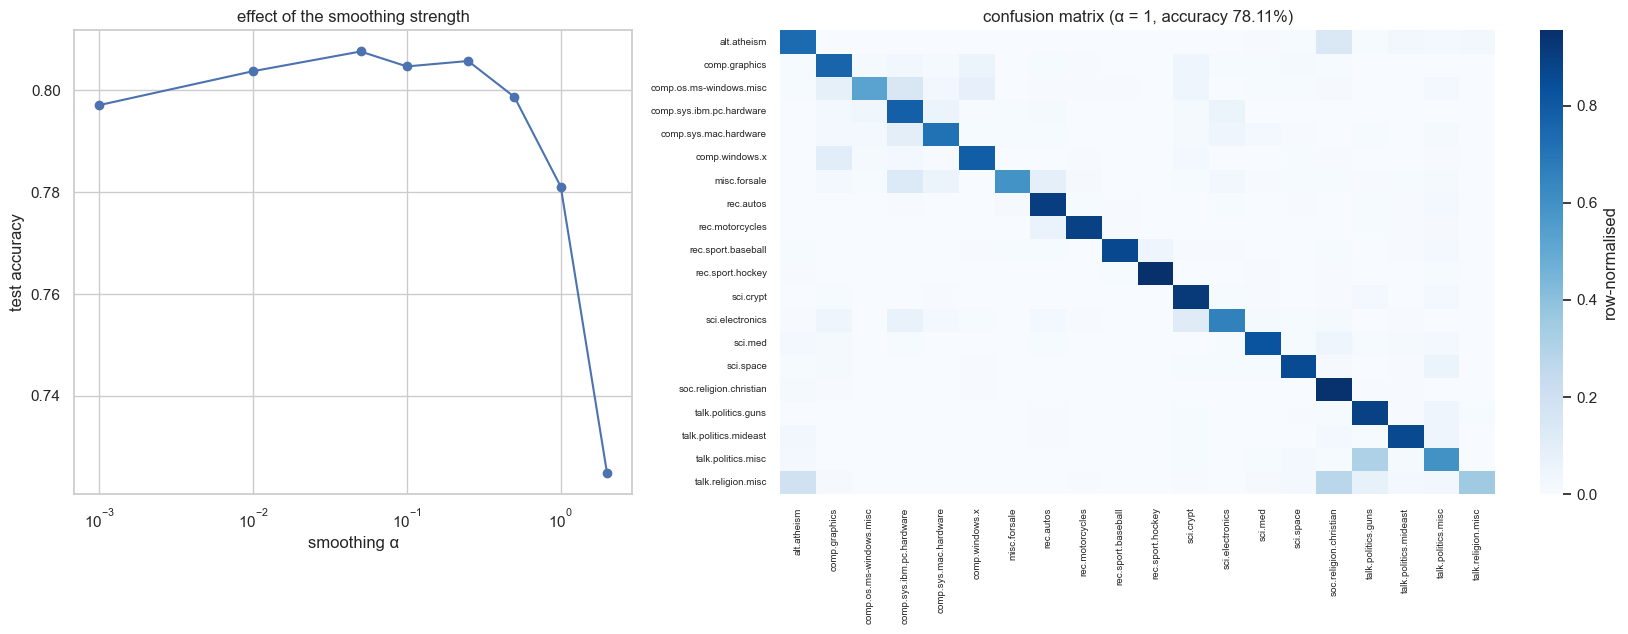

{0.001: np.float64(0.7971), 0.01: np.float64(0.8037), 0.05: np.float64(0.8076), 0.1: np.float64(0.8047), 0.25: np.float64(0.8057), 0.5: np.float64(0.7987), 1.0: np.float64(0.7811), 2.0: np.float64(0.7249)}


In [20]:
alphas = [0.001, 0.01, 0.05, 0.1, 0.25, 0.5, 1.0, 2.0]
acc_alpha = [np.mean(naiveBayesClassify((tr_doc, tr_term, tr_cnt), tr_lab, (te_doc, te_term, te_cnt), a) == te_lab) for a in alphas]
results['q3_alpha_sweep'] = dict(zip(map(str, alphas), np.round(acc_alpha, 4).tolist()))
cm = np.zeros((C, C), int)
np.add.at(cm, (te_lab, pred), 1)
fig, ax = plt.subplots(1, 2, figsize=(17, 6.5), gridspec_kw={'width_ratios': [1, 1.6]})
ax[0].semilogx(alphas, acc_alpha, 'o-'); ax[0].set_xlabel('smoothing α'); ax[0].set_ylabel('test accuracy'); ax[0].set_title('effect of the smoothing strength')
sns.heatmap(cm / cm.sum(1, keepdims=True), cmap='Blues', ax=ax[1], xticklabels=groups, yticklabels=groups, cbar_kws={'label': 'row-normalised'})
ax[1].set_title(f'confusion matrix (α = 1, accuracy {acc:.2%})'); ax[1].tick_params(labelsize=7)
plt.tight_layout(); savefig('q3_results'); plt.show()
print(dict(zip(alphas, np.round(acc_alpha, 4))))

with open('results.json', 'w') as f:
    json.dump(results, f, indent=2, default=float)